In [1]:
# ------------------------------
# Importing necessary libraries
# ------------------------------

# Primary libraries
import pandas as pd
import os
import glob
import requests
import time

from tqdm import tqdm

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# NBA API
from nba_api.stats.endpoints import leaguegamefinder

print("Successfully loaded all libraries!")

Successfully loaded all libraries!


In [2]:
# ---------------------------------------------------
# Downloading NBA games (2019-20 to 2024-25 seasons)
# ---------------------------------------------------

save_dir = "../data/raw/nba"
os.makedirs(save_dir, exist_ok=True)

seasons = [
    "2019-20", "2020-21", "2021-22", "2022-23", "2023-24", "2024-25"
]

errors = []

for season in tqdm(seasons, desc="Downloading seasons"):
    filename_games = f"{save_dir}/nba_games_{season.replace('-', '')}.csv"

    try:
        if os.path.exists(filename_games):
            print(f"Skipping {season}, already downloaded.")
        else:
            gamefinder = leaguegamefinder.LeagueGameFinder(season_nullable=season)
            games = gamefinder.get_data_frames()[0]
            games.to_csv(filename_games, index=False)
            print(f"Saved {season} with {len(games)} games.")

            time.sleep(0.6)

    except Exception as e:
        errors.append(f"Error: {season} - {e}")

print("\nDownload completed!")
if errors:
    print("\nErrors:")
    for e in errors:
        print(e)
else:
    print("No errors!")


Skipping 2019-20, already downloaded.
Skipping 2020-21, already downloaded.
Skipping 2021-22, already downloaded.
Skipping 2022-23, already downloaded.
Skipping 2023-24, already downloaded.
Skipping 2024-25, already downloaded.

Download completed!
No errors!


In [3]:
# ---------------------------------------------------
# Downloading NBA games (2014-15 to 2018-19 seasons)
# ---------------------------------------------------

save_dir = "../data/raw/nba"
os.makedirs(save_dir, exist_ok=True)

seasons = [
    "2014-15", "2015-16", "2016-17", "2017-18", "2018-19"
]

errors = []

for season in tqdm(seasons, desc="Downloading seasons"):
    filename_games = f"{save_dir}/nba_games_{season.replace('-', '')}.csv"

    try:
        if os.path.exists(filename_games):
            print(f"Skipping {season}, already downloaded.")
        else:
            gamefinder = leaguegamefinder.LeagueGameFinder(season_nullable=season)
            games = gamefinder.get_data_frames()[0]
            games.to_csv(filename_games, index=False)
            print(f"Saved {season} with {len(games)} games.")

            time.sleep(0.6)

    except Exception as e:
        errors.append(f"Error: {season} - {e}")

print("\nDownload completed!")
if errors:
    print("\nErrors:")
    for e in errors:
        print(e)
else:
    print("No errors!")


Skipping 2014-15, already downloaded.
Skipping 2015-16, already downloaded.
Skipping 2016-17, already downloaded.
Skipping 2017-18, already downloaded.
Skipping 2018-19, already downloaded.

Download completed!
No errors!


In [4]:
# ------------------------
# Basic data exploration
# ------------------------

df = pd.read_csv("../data/raw/nba/nba_games_202425.csv")

print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"\nColumns:\n{df.columns.tolist()}")

Number of rows: 2802
Number of columns: 28

Columns:
['SEASON_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'PTS', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PLUS_MINUS']


In [ ]:
# ----------------------------------------------------------
# Loading, combining and merging all NBA data (match-level)
# ----------------------------------------------------------

all_files = glob.glob("../data/raw/nba/nba_games_*.csv")

dfs = []

for file in all_files:
    df_temp = pd.read_csv(file, encoding='utf-8', low_memory=False)
    
    basename = os.path.basename(file).replace('.csv', '')
    parts = basename.rsplit('_', 1)
    df_temp['season'] = parts[1]
    
    dfs.append(df_temp)

df_all_raw = pd.concat(dfs, ignore_index=True)

df_all_raw['HOME'] = df_all_raw['MATCHUP'].str.contains("vs").astype(int)  # 1 = home, 0 = away
home = df_all_raw[df_all_raw['HOME'] == 1].copy()
away = df_all_raw[df_all_raw['HOME'] == 0].copy()

df_all = pd.merge(
    home,
    away,
    on=["GAME_ID", "season"],
    suffixes=("_HOME", "_AWAY")
)
df_all['WINNER'] = df_all.apply(lambda row: "HOME" if row['WL_HOME'] == "W" else "AWAY", axis=1)

df_all['GAME_DATE_HOME'] = pd.to_datetime(df_all['GAME_DATE_HOME'], format='mixed')
df_all = df_all.sort_values('GAME_DATE_HOME').reset_index(drop=True)
df_all = df_all.dropna()

print(f"\nTotal rows (matches): {df_all.shape[0]}")
print(f"Total columns: {df_all.shape[1]}")
print(f"Date range: {df_all['GAME_DATE_HOME'].min()} - {df_all['GAME_DATE_HOME'].max()}")
print(f"\nRows per season:")
print(df_all['season'].value_counts().sort_index())


Total rows (matches): 15108
Total columns: 59
Date range: 2014-10-04 00:00:00 - 2025-06-22 00:00:00

Rows per season:
season
201415    1432
201516    1428
201617    1414
201718    1392
201819    1394
201920    1258
202021    1221
202122    1394
202223    1393
202324    1395
202425    1387
Name: count, dtype: int64


In [5]:
# ----------------------------------------------------------
# Loading, combining and merging NBA data (last 6 seasons)
# ----------------------------------------------------------

all_files = glob.glob("../data/raw/nba/nba_games_*.csv")

dfs = []

season_labels = []

for file in all_files:
    basename = os.path.basename(file).replace('.csv', '')
    parts = basename.rsplit('_', 1)
    season_labels.append(parts[1])

selected_seasons = sorted(season_labels)[-6:]
print("Selected seasons:", selected_seasons)

for file in all_files:
    df_temp = pd.read_csv(file, encoding='utf-8', low_memory=False)
    
    basename = os.path.basename(file).replace('.csv', '')
    parts = basename.rsplit('_', 1)
    df_temp['season'] = parts[1]

    if df_temp['season'].iloc[0] in selected_seasons:
        dfs.append(df_temp)

df_all_raw = pd.concat(dfs, ignore_index=True)

df_all_raw['HOME'] = df_all_raw['MATCHUP'].str.contains("vs").astype(int)
home = df_all_raw[df_all_raw['HOME'] == 1].copy()
away = df_all_raw[df_all_raw['HOME'] == 0].copy()

df_all = pd.merge(
    home,
    away,
    on=["GAME_ID", "season"],
    suffixes=("_HOME", "_AWAY")
)

df_all['WINNER'] = df_all.apply(lambda row: "HOME" if row['WL_HOME'] == "W" else "AWAY", axis=1)

df_all['GAME_DATE_HOME'] = pd.to_datetime(df_all['GAME_DATE_HOME'], format='mixed')
df_all = df_all.sort_values('GAME_DATE_HOME').reset_index(drop=True)
df_all = df_all.dropna()

print(f"\nTotal rows (matches): {df_all.shape[0]}")
print(f"Total columns: {df_all.shape[1]}")
print(f"Date range: {df_all['GAME_DATE_HOME'].min()} - {df_all['GAME_DATE_HOME'].max()}")
print(f"\nRows per season:")
print(df_all['season'].value_counts().sort_index())

Selected seasons: ['201920', '202021', '202122', '202223', '202324', '202425']

Total rows (matches): 8048
Total columns: 59
Date range: 2019-09-30 00:00:00 - 2025-06-22 00:00:00

Rows per season:
season
201920    1258
202021    1221
202122    1394
202223    1393
202324    1395
202425    1387
Name: count, dtype: int64


In [6]:
# -----------------------------------------------------------------------------------------------------
# Converting integer columns from float64 to int64 and verifying target variable (WINNER) distribution
# -----------------------------------------------------------------------------------------------------

int_cols = [
    'PTS_HOME', 'PTS_AWAY',
    'REB_HOME', 'REB_AWAY',
    'AST_HOME', 'AST_AWAY',
    'STL_HOME', 'STL_AWAY',
    'BLK_HOME', 'BLK_AWAY',
    'TOV_HOME', 'TOV_AWAY',
    'PF_HOME', 'PF_AWAY',
    'FGM_HOME', 'FGM_AWAY',
    'FGA_HOME', 'FGA_AWAY',
    'FTM_HOME', 'FTM_AWAY',
    'FTA_HOME', 'FTA_AWAY',
    'FG3M_HOME', 'FG3M_AWAY',
    'FG3A_HOME', 'FG3A_AWAY',
    'PLUS_MINUS_HOME', 'PLUS_MINUS_AWAY'
]

df_all[int_cols] = df_all[int_cols].astype(int)

print("Updated data types:")
print(df_all[int_cols].dtypes)

print(f"\nUnique WINNER values: {df_all['WINNER'].unique()}")
print(f"\nWINNER distribution:")
print(df_all['WINNER'].value_counts())
print(f"\nWINNER distribution (%):")
print((df_all['WINNER'].value_counts(normalize=True) * 100).round(1))


Updated data types:
PTS_HOME           int64
PTS_AWAY           int64
REB_HOME           int64
REB_AWAY           int64
AST_HOME           int64
AST_AWAY           int64
STL_HOME           int64
STL_AWAY           int64
BLK_HOME           int64
BLK_AWAY           int64
TOV_HOME           int64
TOV_AWAY           int64
PF_HOME            int64
PF_AWAY            int64
FGM_HOME           int64
FGM_AWAY           int64
FGA_HOME           int64
FGA_AWAY           int64
FTM_HOME           int64
FTM_AWAY           int64
FTA_HOME           int64
FTA_AWAY           int64
FG3M_HOME          int64
FG3M_AWAY          int64
FG3A_HOME          int64
FG3A_AWAY          int64
PLUS_MINUS_HOME    int64
PLUS_MINUS_AWAY    int64
dtype: object

Unique WINNER values: <StringArray>
['HOME', 'AWAY']
Length: 2, dtype: str

WINNER distribution:
WINNER
HOME    4449
AWAY    3599
Name: count, dtype: int64

WINNER distribution (%):
WINNER
HOME    55.3
AWAY    44.7
Name: proportion, dtype: float64


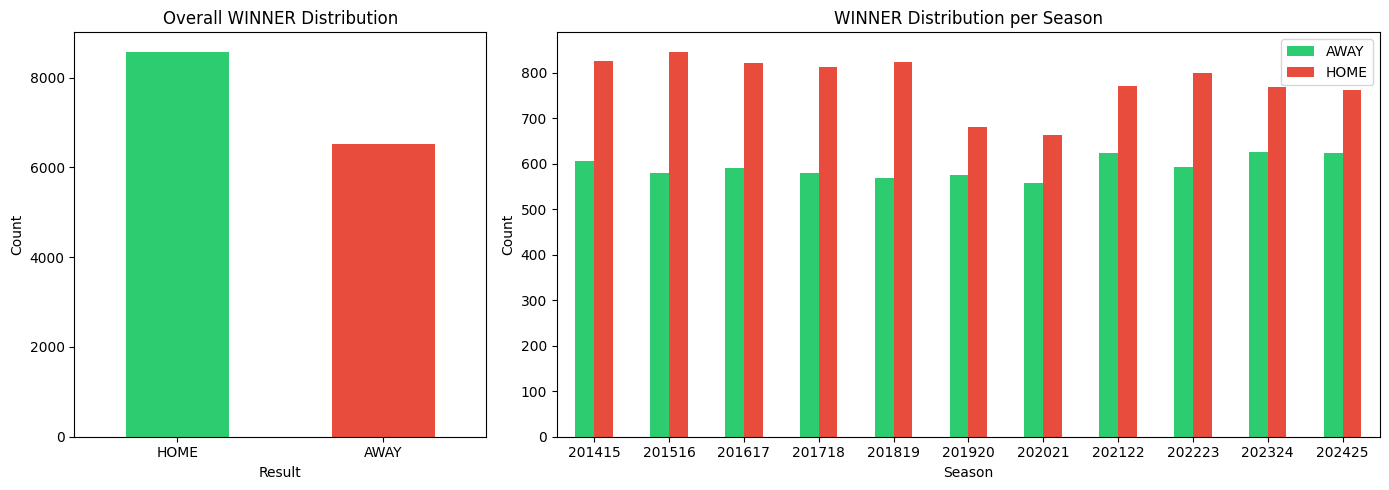

In [11]:
# --------------------------------------------------------------------------------
# Visualising overall WINNER distribution and WINNER distribution per season
# --------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 2]})

winner_counts = df_all['WINNER'].value_counts()
winner_counts.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'], rot=0)
axes[0].set_title('Overall WINNER Distribution')
axes[0].set_xlabel('Result')
axes[0].set_ylabel('Count')

winner_season = df_all.groupby(['season', 'WINNER']).size().unstack()
winner_season.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'], rot=0)
axes[1].set_title('WINNER Distribution per Season')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig('../results/figures/22_winner_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


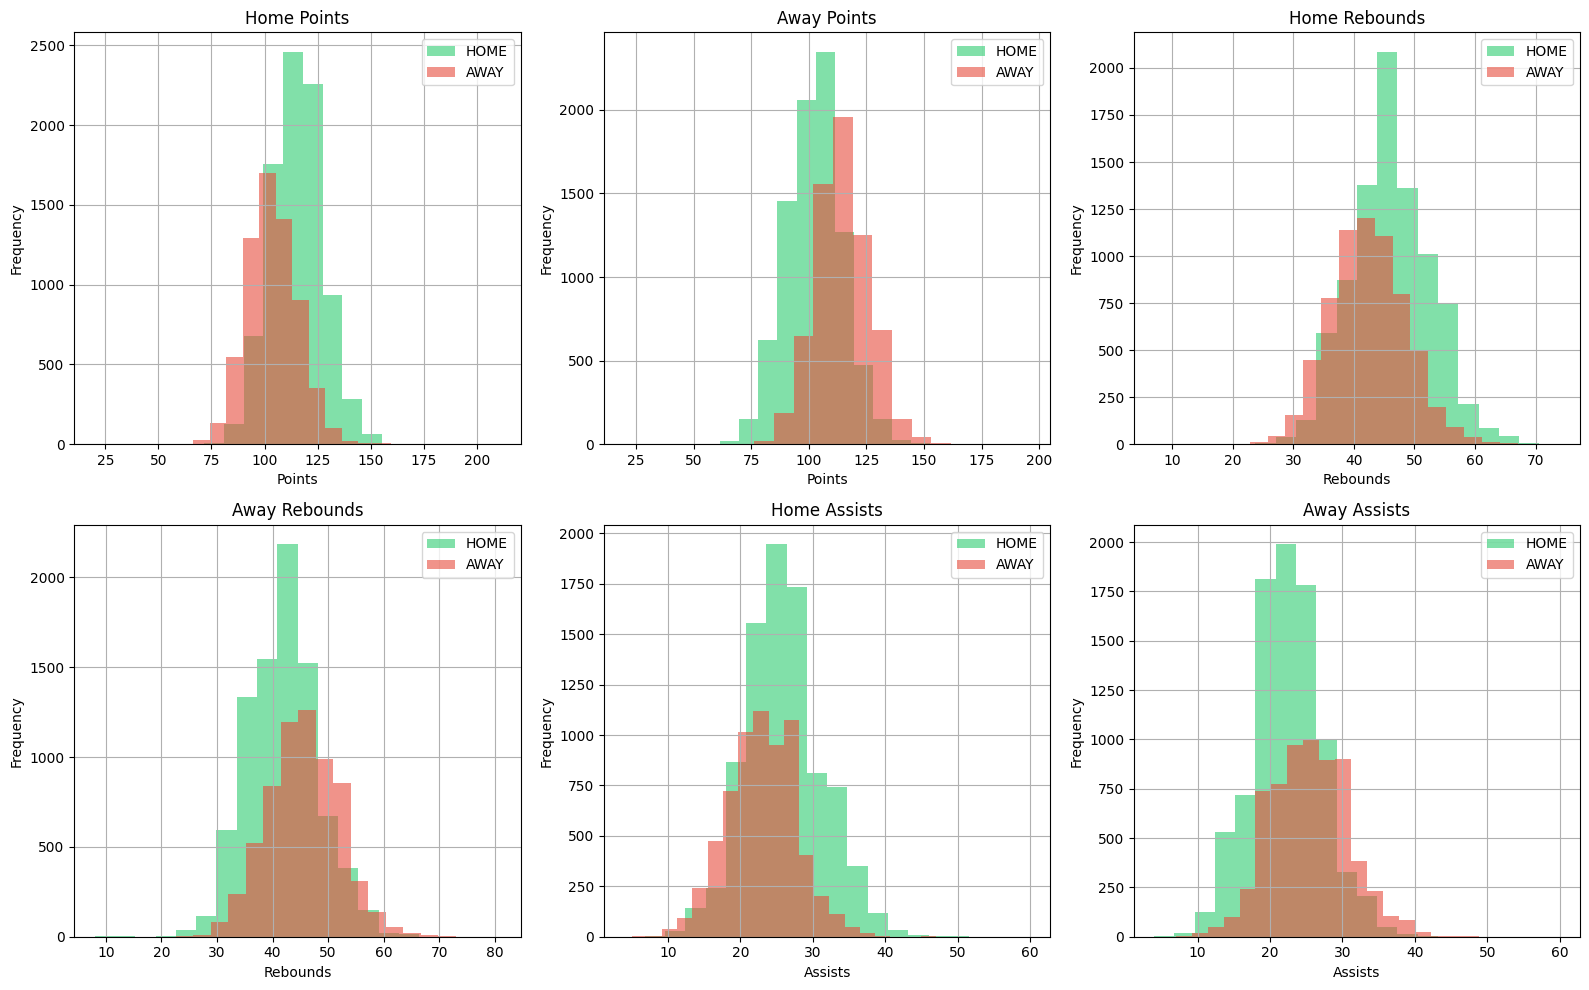

In [12]:
# -------------------------------------------------------------
# Visualising match statistics distribution by result (WINNER)
# -------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

stats = ['PTS_HOME', 'PTS_AWAY', 'REB_HOME', 'REB_AWAY', 'AST_HOME', 'AST_AWAY']
titles = ['Home Points', 'Away Points', 'Home Rebounds', 
          'Away Rebounds', 'Home Assists', 'Away Assists']
x_labels = ['Points', 'Points', 'Rebounds', 'Rebounds', 'Assists', 'Assists']

for i, (stat, title) in enumerate(zip(stats, titles)):
    for result, color in zip(['HOME', 'AWAY'], ['#2ecc71', '#e74c3c']):
        df_all[df_all['WINNER'] == result][stat].hist(
            ax=axes[i], alpha=0.6, color=color, label=result, bins=20
        )
    axes[i].set_title(title)
    axes[i].set_xlabel(x_labels[i])
    axes[i].set_ylabel('Frequency')
    axes[i].legend()

plt.tight_layout()
plt.savefig('../results/figures/23_stats_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


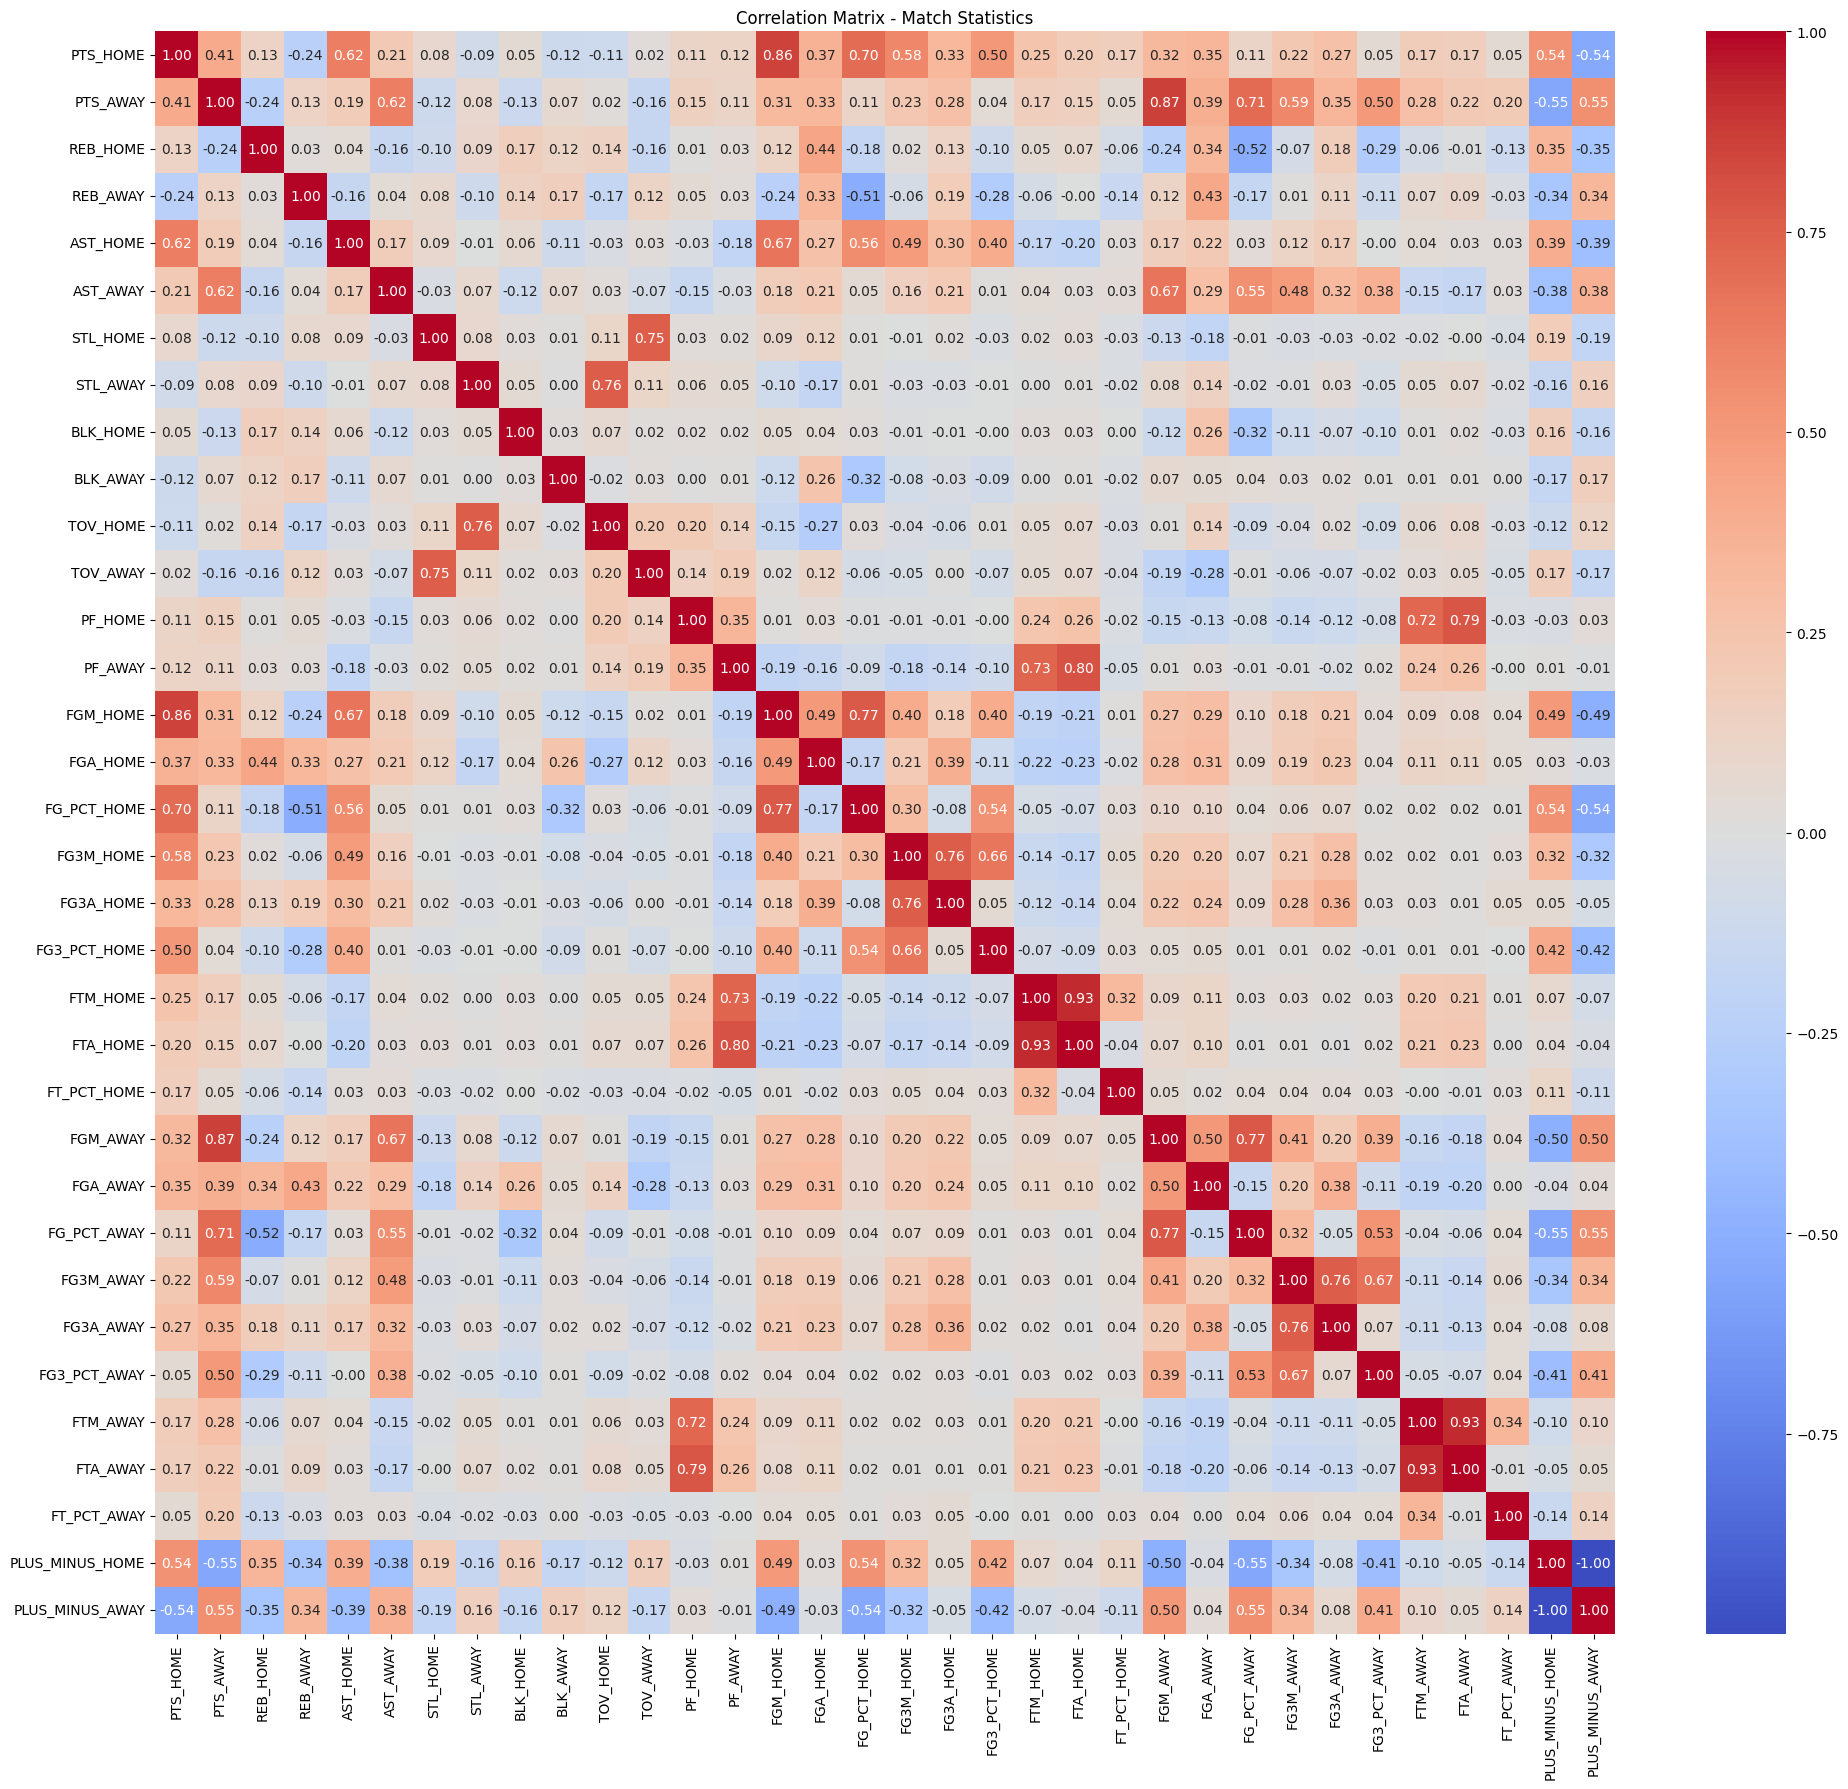

In [18]:
# ----------------------------------------
# Correlation matrix of match statistics
# ----------------------------------------

num_cols = [
    'PTS_HOME', 'PTS_AWAY',
    'REB_HOME', 'REB_AWAY',
    'AST_HOME', 'AST_AWAY',
    'STL_HOME', 'STL_AWAY',
    'BLK_HOME', 'BLK_AWAY',
    'TOV_HOME', 'TOV_AWAY',
    'PF_HOME', 'PF_AWAY',
    'FGM_HOME', 'FGA_HOME', 'FG_PCT_HOME',
    'FG3M_HOME', 'FG3A_HOME', 'FG3_PCT_HOME',
    'FTM_HOME', 'FTA_HOME', 'FT_PCT_HOME',
    'FGM_AWAY', 'FGA_AWAY', 'FG_PCT_AWAY',
    'FG3M_AWAY', 'FG3A_AWAY', 'FG3_PCT_AWAY',
    'FTM_AWAY', 'FTA_AWAY', 'FT_PCT_AWAY',
    'PLUS_MINUS_HOME', 'PLUS_MINUS_AWAY'
]

corr_matrix = df_all[num_cols].corr()

fig, ax = plt.subplots(figsize=(20, 18))
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            ax=ax)

ax.set_title('Correlation Matrix - Match Statistics')
plt.tight_layout()
plt.savefig('../results/figures/24_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# -----------------------------
# Saving cleaned NBA data
# -----------------------------

df_all.to_csv('../data/processed/nba_cleaned_a.csv', index=False)
print(f"Saved {df_all.shape[0]} rows to data/processed/nba_cleaned_a.csv")

In [ ]:
# -----------------------------
# Saving cleaned NBA data
# -----------------------------

df_all.to_csv('../data/processed/nba_cleaned_b.csv', index=False)
print(f"Saved {df_all.shape[0]} rows to data/processed/nba_cleaned_b.csv")

Saved 8048 rows to data/processed/nba_cleaned_b.csv
